# Drift: cambio de mezcla y desempeño

## Pregunta y decisión
¿Un indicador de cambio o una perturbación controlada ayuda a decidir qué revisar en el monitoreo de un modelo? La unidad de análisis es una observación de diagnóstico incluida en un conjunto público; el ejemplo sirve para estudiar métodos de validación y no para uso clínico ni para validar un sistema institucional.

## Datos y fuente
El [conjunto Breast Cancer Wisconsin Diagnostic](https://doi.org/10.24432/C5DW2B) contiene 569 observaciones y 30 variables de imágenes; UCI lo distribuye bajo CC BY 4.0 (Wolberg, Mangasarian, Street y Street, 1993). Se usa la copia incluida en [scikit-learn](https://scikit-learn.org/stable/modules/generated/sklearn.datasets.load_breast_cancer.html). Variable objetivo: maligno = 1. No hay marcas de tiempo ni una validación externa.

**Entorno:** Python, numpy, pandas, matplotlib, scikit-learn, nbformat y Jupyter. Ejecución desde cualquier directorio; no requiere red. Se muestra la versión y huella del dataset transformado para rastrear posibles diferencias de entorno.

**Resultado de esta ejecución:** 200 observaciones de prueba y 74 seleccionadas; la proporción positiva cambia de 37,5 % a 82,4 %. El PSI de 10 intervalos fue 7,48, muy sensible al soporte y a celdas sin observaciones; no debe usarse como umbral universal. Los resultados son descriptivos del corte.

## 1. Preparación y separación de datos

In [1]:
from pathlib import Path
import hashlib
import numpy as np, pandas as pd, matplotlib.pyplot as plt, sklearn
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score, brier_score_loss, confusion_matrix
plt.rcParams.update({'figure.figsize':(8,4.5),'axes.grid':True})
print('scikit-learn:',sklearn.__version__)

scikit-learn: 1.5.2


In [2]:
dataset=load_breast_cancer(as_frame=True)
X=dataset.data.copy(); y=(dataset.target==0).astype(int)  # 1 = maligno
assert len(X)==569 and not X.isna().any().any() and set(y.unique())=={0,1}
print('Observaciones:',len(X),'| Variables:',X.shape[1],'| Positivos (maligno):',int(y.sum()))
print('SHA-256 CSV generado desde matriz y etiqueta:',hashlib.sha256(pd.concat([X,y.rename('maligno')],axis=1).to_csv(index=False).encode()).hexdigest())
X.iloc[:3,:5]

Observaciones: 569 | Variables: 30 | Positivos (maligno): 212
SHA-256 CSV generado desde matriz y etiqueta: e00eccff3e5ac5f9a2d0c1835d45f6a7bcee1b278d890f4c57c531ba45955516


,mean radius,mean texture,mean perimeter,mean area,mean smoothness
0,17.99,10.38,122.8,1001.0,0.11840
1,20.57,17.77,132.9,1326.0,0.08474
2,19.69,21.25,130.0,1203.0,0.10960


In [3]:
X_train,X_test,y_train,y_test=train_test_split(X,y,test_size=0.35,random_state=42,stratify=y)
scaler=StandardScaler().fit(X_train)
z_train=scaler.transform(X_train); z_test=scaler.transform(X_test)
model=LogisticRegression(max_iter=3000,random_state=42).fit(z_train,y_train)
assert set(X_train.index).isdisjoint(X_test.index)
print('Entrenamiento:',len(X_train),'| Prueba:',len(X_test),'| prevalencia prueba:',round(y_test.mean(),3))

Entrenamiento: 369 | Prueba: 200 | prevalencia prueba: 0.375


## 2. Referencia: regresión logística
El escalado se ajusta solo con entrenamiento. El umbral 0,5 es ilustrativo; las métricas no sustituyen calibración, validación externa ni selección de umbral basada en costes. La evaluación se hace sobre las mismas observaciones de prueba en ambas variantes.

In [4]:
def metrics(y_true,score):
    prediction=(score>=0.5).astype(int)
    tn,fp,fn,tp=confusion_matrix(y_true,prediction,labels=[0,1]).ravel()
    return {'n':len(y_true),'prevalencia':np.mean(y_true),'AUC':roc_auc_score(y_true,score) if len(np.unique(y_true))==2 else np.nan,'Brier':brier_score_loss(y_true,score),'sensibilidad':tp/(tp+fn) if tp+fn else np.nan,'falsos_negativos':int(fn),'falsos_positivos':int(fp)}
p_base=model.predict_proba(z_test)[:,1]
pd.Series(metrics(y_test,p_base)).round(4)

n                   200.0000
prevalencia           0.3750
AUC                   0.9972
Brier                 0.0231
sensibilidad          0.9067
falsos_negativos      7.0000
falsos_positivos      0.0000
dtype: float64

## 3. Cambio de mezcla construido sobre observaciones reales
Se selecciona dentro de prueba el 40 % con mayor `mean radius`, usando el percentil 60 del entrenamiento. Es una selección artificial, no un periodo futuro ni una muestra independiente del conjunto completo de prueba.

El PSI compara proporciones por intervalos derivados **solo del entrenamiento** y usa suavización 1e-6. La estadística depende de los cortes; no es probabilidad de fallo ni mide por sí sola degradación. KS es distancia descriptiva, sin p-valor ni supuesto de muestreo temporal.

In [5]:
from scipy.stats import ks_2samp
feature='mean radius'; cutoff=X_train[feature].quantile(.60)
mask=(X_test[feature]>=cutoff).to_numpy()
assert mask.sum()>0 and (~mask).sum()>0
sub=pd.DataFrame([metrics(y_test,p_base),metrics(y_test.to_numpy()[mask],p_base[mask])],index=['prueba completa','subconjunto seleccionado'])
sub.round(4)

,n,prevalencia,AUC,Brier,sensibilidad,falsos_negativos,falsos_positivos
prueba completa,200,0.3750,0.9972,0.0231,0.9067,7,0
subconjunto seleccionado,74,0.8243,1.0000,0.0228,0.9508,3,0


## 4. PSI y KS con sensibilidad al número de intervalos

In [6]:
def psi(ref,actual,bins):
    edges=np.unique(np.quantile(ref,np.linspace(0,1,bins+1)))
    edges[0],edges[-1]=-np.inf,np.inf
    r=np.histogram(ref,edges)[0]/len(ref); a=np.histogram(actual,edges)[0]/len(actual)
    r=(r+1e-6)/(1+1e-6*len(r));a=(a+1e-6)/(1+1e-6*len(a))
    return float(((a-r)*np.log(a/r)).sum()),len(r)
ref=X_train[feature].to_numpy();selected=X_test.loc[mask,feature].to_numpy()
sensitivity=pd.DataFrame([{'bins_solicitados':k,'PSI':psi(ref,selected,k)[0],'bins_efectivos':psi(ref,selected,k)[1]} for k in [5,10,20]])
print('KS descriptivo:',round(ks_2samp(ref,selected).statistic,4))
sensitivity.round(4)

KS descriptivo: 0.6071


,bins_solicitados,PSI,bins_efectivos
0,5,7.8612,5
1,10,7.4849,10
2,20,7.1162,20


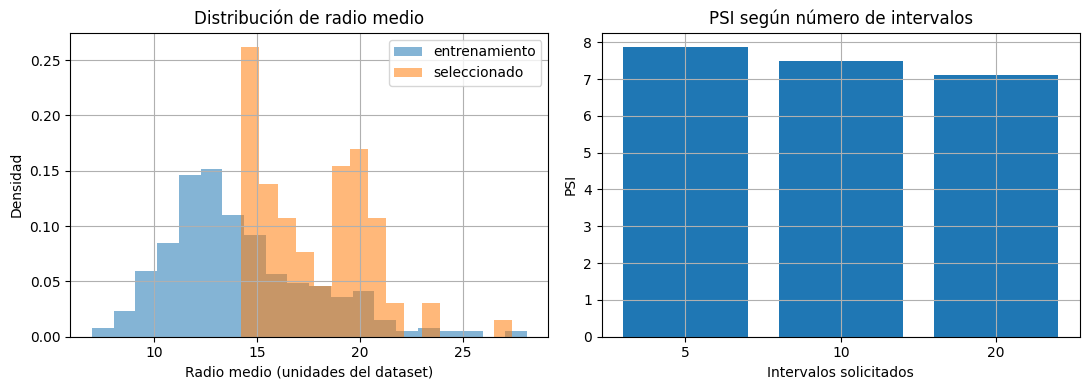

In [7]:
fig,axs=plt.subplots(1,2,figsize=(11,4))
axs[0].hist(ref,bins=20,density=True,alpha=.55,label='entrenamiento');axs[0].hist(selected,bins=15,density=True,alpha=.55,label='seleccionado');axs[0].set(title='Distribución de radio medio',xlabel='Radio medio (unidades del dataset)',ylabel='Densidad');axs[0].legend()
axs[1].bar(sensitivity.bins_solicitados.astype(str),sensitivity.PSI);axs[1].set(title='PSI según número de intervalos',xlabel='Intervalos solicitados',ylabel='PSI');plt.tight_layout();plt.show()

## 5. Incertidumbre de la discriminación
Bootstrap estratificado por etiqueta con 1.000 remuestreos y semilla fija; mide variabilidad condicional a este conjunto de prueba y al modelo ya entrenado. No incorpora incertidumbre del entrenamiento ni reemplaza validación externa. Los intervalos de los conjuntos se solapan porque el subconjunto pertenece al conjunto completo.

In [8]:
rng=np.random.default_rng(42)
def auc_bootstrap(y,score,draws=1000):
    y=np.asarray(y);score=np.asarray(score);positive=np.flatnonzero(y==1);negative=np.flatnonzero(y==0)
    if not len(positive) or not len(negative): return [np.nan,np.nan]
    values=[]
    for _ in range(draws):
        idx=np.r_[rng.choice(positive,len(positive),replace=True),rng.choice(negative,len(negative),replace=True)]
        values.append(roc_auc_score(y[idx],score[idx]))
    return np.quantile(values,[.025,.975])
ci_all=auc_bootstrap(y_test,p_base);ci_sub=auc_bootstrap(y_test.to_numpy()[mask],p_base[mask])
pd.DataFrame([{'muestra':'prueba completa','AUC':roc_auc_score(y_test,p_base),'IC_2.5%':ci_all[0],'IC_97.5%':ci_all[1]},{'muestra':'subconjunto seleccionado','AUC':roc_auc_score(y_test.to_numpy()[mask],p_base[mask]),'IC_2.5%':ci_sub[0],'IC_97.5%':ci_sub[1]}]).round(4)

,muestra,AUC,IC_2.5%,IC_97.5%
0,prueba completa,0.9972,0.9919,1.0
1,subconjunto seleccionado,1.0000,1.0000,1.0


## 6. Interpretación y límites
Compare en las tablas el desempeño del conjunto completo con el subconjunto. La selección puede cambiar la prevalencia y dificultad; la diferencia no identifica su causa, y las muestras se solapan. Sin fechas, ni etiquetas de producción, ni umbrales previos, no se estima deriva temporal real ni eficacia del monitoreo. Como siguiente paso se requieren datos de predicción fechados, etiquetas maduras, ventanas de referencia e intervención documentadas.